In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_ta as ta

%load_ext autoreload
%autoreload 2

from Engine.DataTimeseries import DataTimeseries
from Engine.Backtester import Backtester
from Engine.Utils import timeframe_to_minutes



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [77]:
data = DataTimeseries('./Data/nq_continous.csv')
data.resample_data('1H')
data.convert_timezone('America/New_York')

data.slice(start_date=pd.Timestamp(year=2010, month=1, day=1))  # only include data after 2018
IS_data, OOS_data = data.split(split_date=pd.Timestamp(year=2023, month=1, day=1))

df = IS_data.get_ohlc_prices_series()
df


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows



/Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/Engine/DataTimeseries.py:114: FutureWarning:

'H' is deprecated and will be removed in a future version, please use 'h' instead.



,Open,High,Low,Close
Time,,,,
2010-06-06 21:00:00-04:00,1826.25,1827.50,1811.50,1815.75
2010-06-06 22:00:00-04:00,1816.00,1818.00,1811.75,1813.00
2010-06-06 23:00:00-04:00,1813.00,1821.75,1812.50,1819.75
2010-06-07 00:00:00-04:00,1819.00,1822.50,1815.75,1820.50
2010-06-07 01:00:00-04:00,1820.25,1823.25,1818.75,1823.25
...,...,...,...,...
2022-12-30 13:00:00-05:00,10946.50,10956.75,10929.25,10955.25
2022-12-30 14:00:00-05:00,10955.50,10956.00,10875.00,10906.75
2022-12-30 15:00:00-05:00,10907.00,10913.25,10882.75,10904.75


In [84]:
# EWMAC of 4-16, 8-32, 16-64, 32-128, 64-256
import math
import optuna

ema4 = ta.ema(df['Close'], length=4)
ema8 = ta.ema(df['Close'], length=8)
ema16 = ta.ema(df['Close'], length=16)
ema32 = ta.ema(df['Close'], length=32)
ema64 = ta.ema(df['Close'], length=64)
ema128 = ta.ema(df['Close'], length=128)
ema256 = ta.ema(df['Close'], length=256)

pct_change = df['Close'].diff().fillna(0)
price_volatility = pct_change.ewm(span=32).std()

# calculate raw forecasts and normalize by volatility
# we normalize by volatility because the movement of price isn't consistent
# for example, a 1% move in 2010 might have been $80, but now a 1% move might be $240
# this allows us to calculate a general forecast on every instrument and at any time 
raw_forecast_4_16 = (ema4 - ema16) / price_volatility
raw_forecast_8_32 = (ema8 - ema32) / price_volatility
raw_forecast_16_64 = (ema16 - ema64) / price_volatility
raw_forecast_32_128 = (ema32 - ema128) / price_volatility
raw_forecast_64_256 = (ema64 - ema256) / price_volatility

# we include all the scalars EWMAC(N,4N) so long as the trading costs are incredibly high
# all scalars N and 2N-6N are heavily correlated in terms of returns

# create a forecast which is the conviction on the current EWMAC(N, 4N) of which way the market is moving
# scaled so the mean(abs(distribution)) ~= 10, carver uses 10 as a target we may consider modifying
# all the means of each distribution will be positive (u>0) because price trends up overtime (beta)

# we have to scale all the means because the distributions are independently normal but not scaled to the same degree
# the raw_forecast_4_16 may produce a value of 0.02 and the raw_forecast_64_256 may produce 0.62, these could have the
# same z-score, but we wouldnt know this unless we scale all the means to be the same

# Why scale to +10? The value of +10 is just for human understanding +20 is 2x the avg position (+10)
# the means of the distributions are all slightly positive(beta), so generally be ever so slightly long biased
 
# the idea is to center the distribution(normal hopefully) around 10 so its easy to tell
# how strong conviction is, 0.5432 vs 15 or 5


# figure out the forecast scalars so the mean on the raw forecasts is centered at 10
target = 10
print(f'forecast_scalar_4_16 = {target / raw_forecast_4_16.abs().mean()}')
print(f'forecast_scalar_8_32 = {target / raw_forecast_8_32.abs().mean()}')
print(f'forecast_scalar_16_64 = {target / raw_forecast_16_64.abs().mean()}')
print(f'forecast_scalar_32_128 = {target / raw_forecast_32_128.abs().mean()}')
print(f'forecast_scalar_64_256 = {target / raw_forecast_64_256.abs().mean()}')

forecast_scalar_4_16 = 9.958026854089237
forecast_scalar_8_32 = 6.502315023780024
forecast_scalar_16_64 = 4.188764847539494
forecast_scalar_32_128 = 2.7597249677251194
forecast_scalar_64_256 = 1.857735393914461

scaled_forecast_4_16 = raw_forecast_4_16 * forecast_scalar_4_16
scaled_forecast_8_32 = raw_forecast_8_32 * forecast_scalar_8_32
scaled_forecast_16_64 = raw_forecast_16_64 * forecast_scalar_16_64
scaled_forecast_32_128 = raw_forecast_32_128 * forecast_scalar_32_128
scaled_forecast_64_256 = raw_forecast_64_256 * forecast_scalar_64_256



# original strategy says to clip between [-20, 20]
# however this is on the daily timeframe, [-20, 20] clip is about 3-sigma so 99.7% of the time
# to calculate the clip value, calculate the value 3 sigma from the mean, i chose 40
print(f'\n3-sigma values:')
print(f'scaled_forecast_4_16_clip = {scaled_forecast_4_16.mean() + 3 *scaled_forecast_4_16.std()}')
print(f'scaled_forecast_8_32_clip = {scaled_forecast_8_32.mean() + 3 *scaled_forecast_8_32.std()}')
print(f'scaled_forecast_16_64_clip = {scaled_forecast_16_64.mean() + 3 * scaled_forecast_16_64.std()}')
print(f'scaled_forecast_32_128_clip = {scaled_forecast_32_128.mean() + 3 * scaled_forecast_32_128.std()}')
print(f'scaled_forecast_64_256_clip = {scaled_forecast_64_256.mean() + 3 * scaled_forecast_64_256.std()}')


clip_value = 40
clipped_scaled_forecast_4_16 = np.clip(scaled_forecast_4_16, -clip_value, clip_value)
clipped_scaled_forecast_8_32 = np.clip(scaled_forecast_8_32, -clip_value, clip_value)
clipped_scaled_forecast_16_64 = np.clip(scaled_forecast_16_64, -clip_value, clip_value)
clipped_scaled_forecast_32_128 = np.clip(scaled_forecast_32_128, -clip_value, clip_value)
clipped_scaled_forecast_64_256 = np.clip(scaled_forecast_64_256, -clip_value, clip_value)

weighted_forecast = (
    clipped_scaled_forecast_4_16 * 0.2 +
    clipped_scaled_forecast_8_32 * 0.2 +
    clipped_scaled_forecast_16_64 * 0.2 +
    clipped_scaled_forecast_32_128 * 0.2 +
    clipped_scaled_forecast_64_256 * 0.2
)

signal = np.where(weighted_forecast > 0, 1, -1)  

forecast_scalar_4_16 = 9.42038715084509
forecast_scalar_8_32 = 6.217377693544527
forecast_scalar_16_64 = 4.109046628733621
forecast_scalar_32_128 = 2.74117727805526
forecast_scalar_64_256 = 1.8556901612061913

3-sigma values:
scaled_forecast_4_16_clip = 41.5398204877143
scaled_forecast_8_32_clip = 41.00837904175933
scaled_forecast_16_64_clip = 40.4361509136549
scaled_forecast_32_128_clip = 40.582240782198085
scaled_forecast_64_256_clip = 40.09579424108366


In [ ]:

# # weight each of the individual forecasts
# w1 = 0.2
# w2 = 0.2
# w3 = 0.2
# w4 = 0.2
# w5 = 0.2

# def generate_forecast(w1, w2, w3, w4, w5):
#     norm = w1 + w2 + w3 + w4 + w5
#     w1 = w1 / norm
#     w2 = w2 / norm
#     w3 = w3 / norm
#     w4 = w4 / norm
#     w5 = w5 / norm

#     weighted_combined_forecast = (
#         clipped_scaled_forecast_4_16 * w1 +
#         clipped_scaled_forecast_8_32 * w2 +
#         clipped_scaled_forecast_16_64 * w3 +
#         clipped_scaled_forecast_32_128 * w4 +
#         clipped_scaled_forecast_64_256 * w5
#     )
    
#     return weighted_combined_forecast

# def objective(trial):
#     w1 = trial.suggest_float('w1', 0, 100)
#     w2 = trial.suggest_float('w2', 0, 100)
#     w3 = trial.suggest_float('w3', 0, 100)
#     w4 = trial.suggest_float('w4', 0, 100)
#     w5 = trial.suggest_float('w5', 0, 100)

#     weighted_combined_forecast = generate_forecast(w1, w2, w3, w4, w5)
#     signal = np.where(weighted_combined_forecast > 0, 1, -1)
#     bt = Backtester(
#         IS_data.get_ohlc_prices(),
#         IS_data.get_indicies(),
#         signal,
#         IS_data.get_timeframe(),
#         tick_value=0.5,
#         contract_multiplier=2,
#         slippage_ticks=2,
#         commission=0.5
#     )
#     bt.quick_backtest()
#     return bt.final_equity

# study = optuna.create_study(direction='maximize')
# study.optimize(lambda trial: objective(trial), n_trials=1000)
# best_weights_unnormalized = study.best_params

# print(best_weights_unnormalized)
# w1 = best_weights_unnormalized['w1']
# w2 = best_weights_unnormalized['w2']
# w3 = best_weights_unnormalized['w3']
# w4 = best_weights_unnormalized['w4']
# w5 = best_weights_unnormalized['w5']

# weighted_combined_forecast = generate_forecast(w1, w2, w3, w4, w5)
# df['signal'] = np.where(weighted_combined_forecast > 0, 1, -1)

# weighted_sum = (
#     clipped_scaled_forecast_4_16 * 0.2 +
#     clipped_scaled_forecast_8_32 * 0.2 +
#     clipped_scaled_forecast_16_64 * 0.2 +
#     clipped_scaled_forecast_32_128 * 0.2 +
#     clipped_scaled_forecast_64_256 * 0.2
# )
# signal = np.where(weighted_sum > 0, 1, -1)


In [ ]:
# position sizing
# position size= (forecast × volatility_target × capital) / instrument volatility

# FORECAST - scaled between [-clip, clip] 

# VOLATILITY TARGET - what percentage of your risk are you willing to put up per trade
# vol_target = 0.01 means “risk 1% of capital per 1σ move in the instrument.”

# CAPITAL - the dollar amount you are willing to allocate to this system
# Position size is proportional to your capital
# If your capital doubles, your positions double

# INSTRUMENT VOLATILITY 
# typically we want to scale our positions down when volatility is high and scale up when volatility low
# this may seem counterintuative to make money, but this maintains a constant risk exposure and proves more
# successful in the long run

volatility_target = 0.01
capital = 100_000

# normalize the forecast between [-1, 1]
position_size = weighted_forecast / clip_value
position_size = (position_size * volatility_target * capital) / price_volatility
position_size = np.clip(position_size, -20, 20)

In [18]:
from Graphics.Chart import Chart


chart = Chart(IS_data.get_ohlc_prices(), IS_data.get_indicies())
chart.add_custom_indicator(signal, 'Signal', panel=1)
chart.show()

count    75055.000000
mean         1.854746
std         13.228358
min        -60.872055
25%         -6.644977
50%          2.291053
75%         10.570995
max         52.239324
dtype: float64

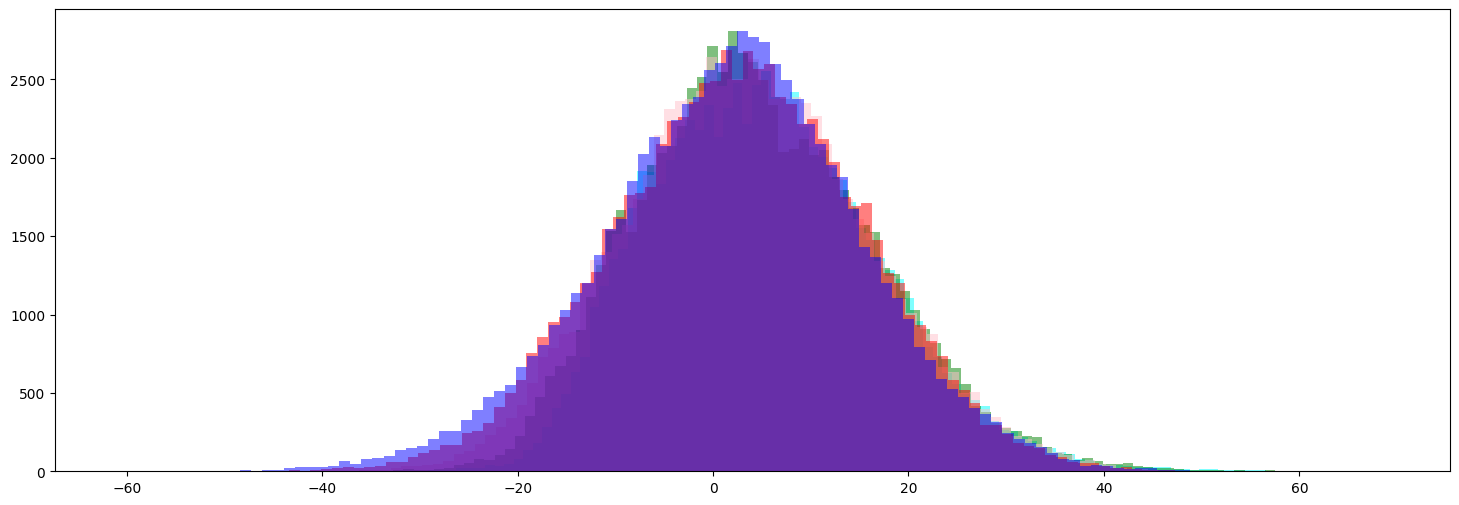

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 6))
plt.hist(scaled_forecast_64_256, bins=100, color='aqua', alpha=0.5)
plt.hist(scaled_forecast_32_128, bins=100, color='green', alpha=0.5)
plt.hist(scaled_forecast_16_64, bins=100, color='pink', alpha=0.5)
plt.hist(scaled_forecast_8_32, bins=100, color='red', alpha=0.5)
plt.hist(scaled_forecast_4_16, bins=100, color='blue', alpha=0.5)

scaled_forecast_4_16.describe()



        Backtest Results from 2010-06-06 21:00:00-04:00 to 2022-12-30 17:00:00-05:00 (4589 days 21:00:00)
        Equity:     $100,000.00 -> $117,337.50
        Buy & Hold: $100,000.00 -> $608,109.60
        Buy & Hold Return (%): 508.11%
        Strategy Return (%):   17.34%

        Total Trades:     2143.00
        Win Rate:         28.98%
        95% CI:           27.10% - 30.94%
        Avg. Win:         $194.86
        Avg. Loss:        $-68.52
        Ratio Win/Loss:   2.84
        Expected Value:   $7.80

        Largest Win:      $3,474.00
        Largest Loss:     $-957.00
        Max Consec. Wins: 21
        Max Consec. Loss: 21

        Max Drawdown from 2020-03-18 14:00:00-04:00 to 2020-04-05 20:00:00-04:00 (18 days 06:00:00)
        Max Drawdown:     $-4,020.50
        Max Drawdown (%): -3.40%

        Slippage:   2 ticks
        Commission: $0.50
        Contract Multiplier: $2.00
        Transaction Costs:   $3,213.00

        CAGR:              1.28%
        Sharpe Ra

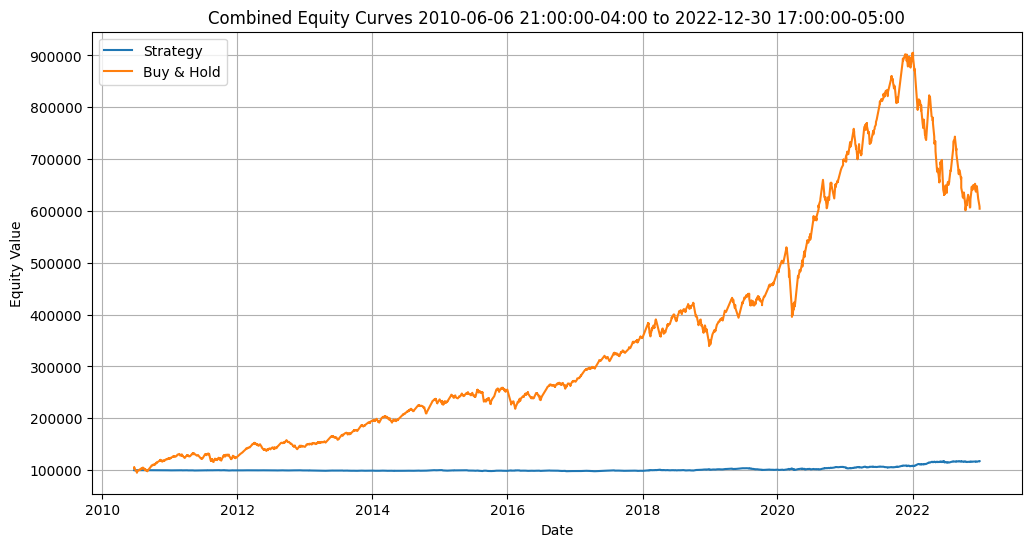

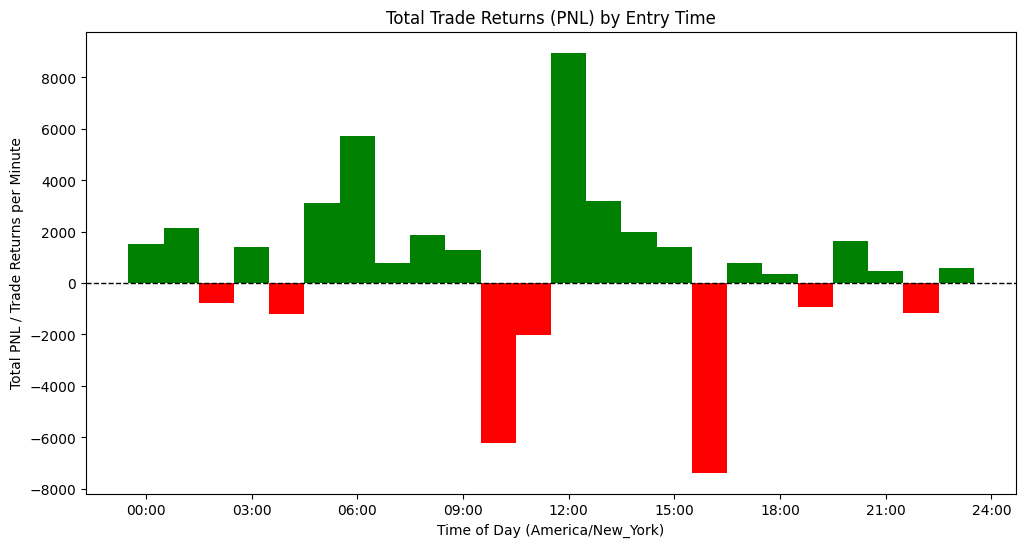

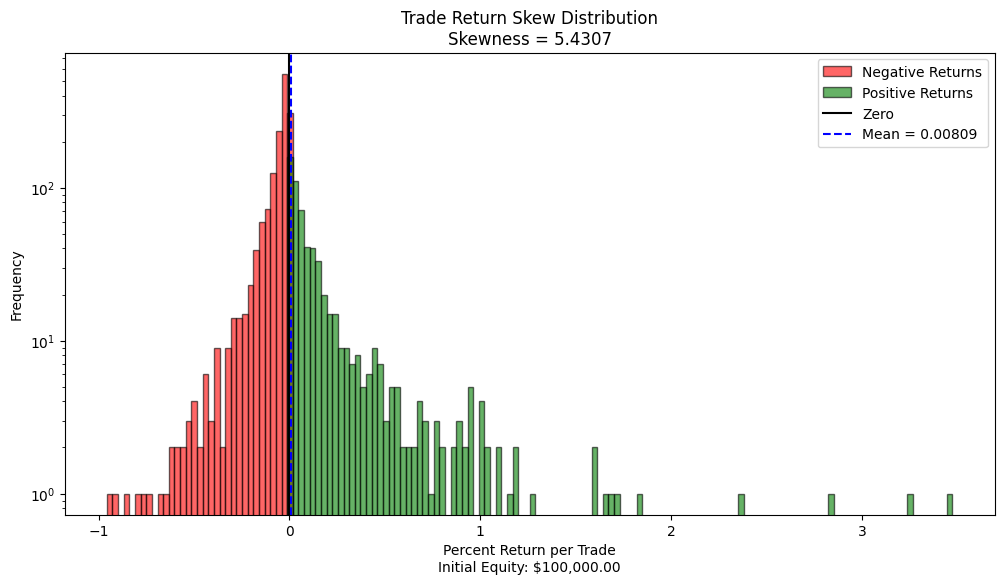

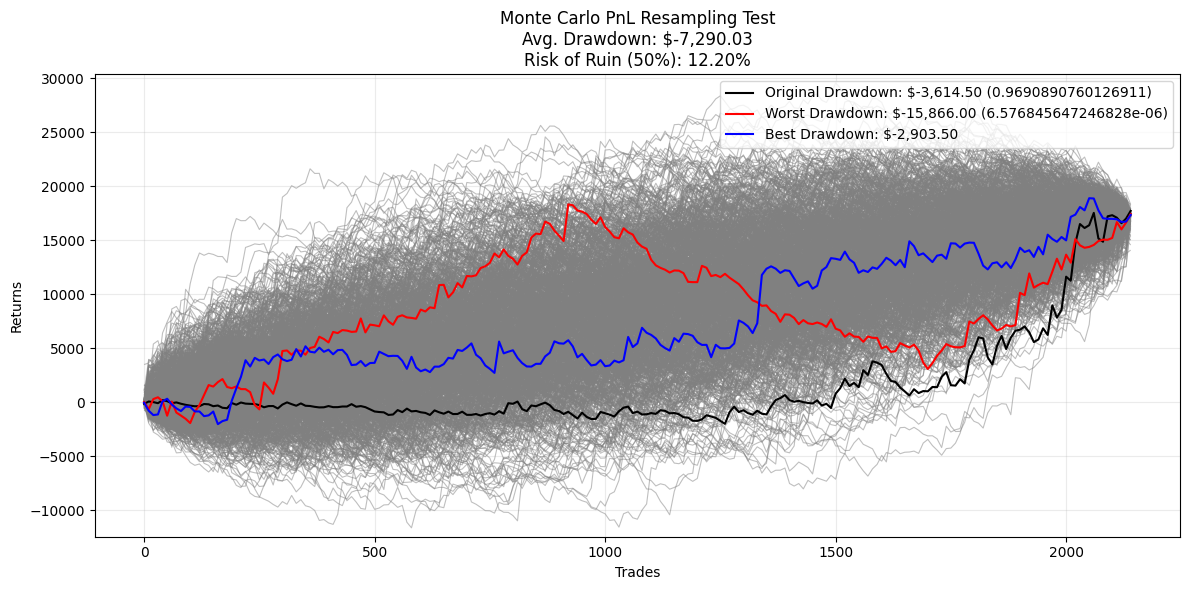

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


/Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/Engine/Backtester.py:537: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



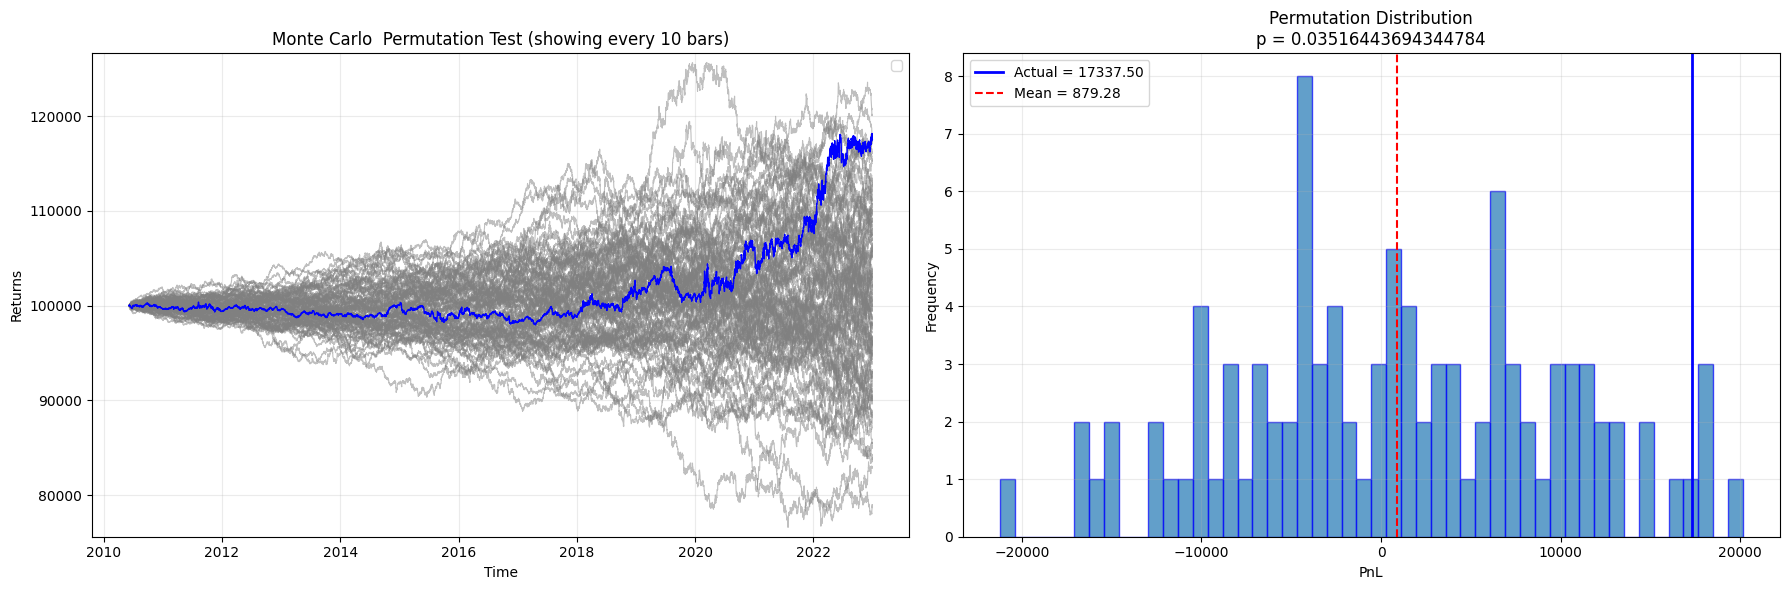

In [85]:
from Engine.EquityCurve import EquityCurve


bt = Backtester(
    IS_data.get_ohlc_prices(),
    IS_data.get_indicies(),
    signal,
    IS_data.get_timeframe(),
    tick_value=0.5,
    contract_multiplier=2,
    slippage_ticks=2,
    commission=0.5
)
bt.full_backtest()
print(bt)
returns = pd.Series(bt.trade_pnl).groupby(bt.trade_indicies.cumsum()).sum()

equity_curve = bt.generate_equity_curve()
bh_curve = bt.generate_buy_hold_equity_curve()
EquityCurve.combine_equity_curves([equity_curve, bh_curve], ['Strategy', 'Buy & Hold'])

bt.generate_trade_time_distribution()
bt.generate_skew_curve().plot()
bt.monte_carlo_pnl_resampling_test(iterations=1000, pct_of_trades=0.1)
bt.monte_carlo_permutation_test(iterations=100, pct_of_trades=0.1)